# 41 - Likelihood-targeted unlearning and the calibration axis

Stage 1 (2026-09-08) showed that every post-hoc method lands either short of the point retraining
reaches (the retain fine-tune undoes the edit through shared parameters) or past it (the objective
has no stopping point), and that none costs utility. The natural summary is one axis: the forget
cells' negative ELBO. The baseline fits the 30 megakaryocytes far better than a clean retrain, which
never saw them, fits them; the edit-then-fine-tune methods land short of the retrain level and the
continuous-objective methods land past it (`outputs/p6/phase_audit.json`).

**Part A** places every re-derived checkpoint on that axis with one instrument set: forget-set
negative ELBO, the canonical MLP attacker, and the reference likelihood-ratio audit. Every likelihood
in this notebook uses the deterministic estimator of `src/likelihood_audit.py` (eval mode, sixteen
seeded z samples), the same one as `scripts/attack_lr_reference.py`.

**Part B** tests whether giving a method the target fixes it. Likelihood-targeted unlearning (LTU,
`src/train_targeted_unlearn.py`) fine-tunes on the retain set with a two-sided penalty that pulls
each forget cell's negative ELBO to the model's own negative ELBO on that cell's k nearest matched
negatives. The target needs no retrain: it is the never-seen level the evaluation protocol already
measures. Ten seeds, training curves, a weight ablation, and the final models on the axis.

**Part C** changes the target from the ten nearest look-alikes to the cohort average, the model's own
negative ELBO over all matched negatives, which is where the clean retrain fits the forget cells.

**Part D** repeats Part C with a calibration set disjoint from the evaluation negatives.

In [1]:
import sys
sys.path.insert(0, '../src')
sys.path.insert(0, '../scripts')

import json
import numpy as np
import pandas as pd
import torch
import scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score

import eval_multiseed as EM
EM.DEVICE = 'cpu'   # MIA scoring is CPU throughout (MPS is not bit-reproducible)
from eval_multiseed import (load_vae_model, train_fresh_attacker, evaluate_utility, MARKER_GENES,
                            DATA_PATH, SPLIT_PATH, MATCHED_NEG_PATH, BASELINE_CHECKPOINT)
from save_persample_scores import checkpoint_map
from train_targeted_unlearn import (neg_elbo_per_cell, matched_neighbors, attack_features, retain_latents,
                                    Evaluator, train_targeted)
from canonical import pbmc_success_threshold, pbmc_null_floor

plt.style.use('seaborn-v0_8-whitegrid')
TRAIN_DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
OUTPUT_DIR = Path('../outputs/p7')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REF_PATH = Path('../outputs/p1/retrain_clean/seed_42/best_model.pt')
print(f'training device: {TRAIN_DEVICE}; scoring device: cpu')

training device: mps; scoring device: cpu


In [2]:
adata = sc.read_h5ad(DATA_PATH)
split = json.load(open(SPLIT_PATH))
forget_idx, retain_idx, unseen_idx = split['forget_indices'], split['retain_indices'], split['unseen_indices']
matched_idx = json.load(open(MATCHED_NEG_PATH))['matched_indices']
X = torch.tensor(adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X, dtype=torch.float32)
X_forget, X_matched, X_retain = X[forget_idx], X[matched_idx], X[retain_idx]
X_holdout, labels_holdout = X[unseen_idx], adata.obs['leiden'].values[unseen_idx]
gene_names = list(adata.var_names)
marker_idx = [gene_names.index(g) for g in MARKER_GENES if g in gene_names]
rs = np.random.RandomState(42).choice(retain_idx, 5000, replace=False)
X_retain_sample = X[rs]
labels = np.r_[np.ones(len(forget_idx)), np.zeros(len(matched_idx))]

baseline, _ = load_vae_model(str(BASELINE_CHECKPOINT))
reference, _ = load_vae_model(str(REF_PATH))
attacker = train_fresh_attacker(baseline, adata, forget_idx, matched_idx, retain_idx)
attacker.eval()
neighbors = matched_neighbors(baseline, X_forget, X_matched, 'cpu', k=10)
evaluator = Evaluator(attacker, reference, X_forget, X_matched, X_retain_sample, 'cpu')
print(f'forget {len(forget_idx)}, matched negatives {len(matched_idx)}, retain {len(retain_idx)}')

Training fresh attacker on baseline F vs matched:
  Samples: 224 (30 forget + 194 matched)
  Features: 70 dims
  Train: 179, Test: 45


  Baseline AUC (F vs matched, full set): 0.8017
  (Canonical NB03 value: ~0.769)
forget 30, matched negatives 194, retain 28094


## Part A: every checkpoint on the calibration axis

One instrument set for every re-derived checkpoint: forget-set negative ELBO, matched-negative
negative ELBO, the canonical attacker's AUC, and the reference audit (negative ELBO under clean retrain
seed 42 minus negative ELBO under the checkpoint; near 1 means the forget cells are still fitted better
than a never-trained model fits them, near 0 means worse).

In [3]:
def families():
    fam = dict(checkpoint_map())
    fam.pop('retrain_leaky', None)
    base = Path('../outputs')
    for p in sorted((base / 'rau').glob('rau_lambda*_model.pt')):
        fam.setdefault('rau', []).append((p.stem.split('_')[1], p))
    for p in sorted((base / 'augmentation').glob('pbmc_aug*_model.pt')):
        fam.setdefault('augmentation', []).append((p.stem.split('_')[1], p))
    return fam

rows = []
for method, seeds in families().items():
    for sd, path in seeds:
        model, _ = load_vae_model(str(path))
        m = evaluator(model, neighbors)
        rows.append({'method': method, 'seed': str(sd), **m})
axis = pd.DataFrame(rows)
axis.to_csv(OUTPUT_DIR / 'calibration_axis.csv', index=False)
summary = axis.groupby('method')[['forget_neg_elbo', 'matched_neg_elbo', 'mlp_auc', 'lr_auc']].mean().round(3)
summary['n'] = axis.groupby('method').size()
summary.sort_values('forget_neg_elbo')

,forget_neg_elbo,matched_neg_elbo,mlp_auc,lr_auc,n
method,,,,,
baseline,269.489,333.126,0.802,0.996,1
augmentation,277.601,331.897,0.760,0.985,2
moon,292.309,334.032,0.740,0.996,3
ssd,296.253,332.639,0.701,0.995,3
scrub,296.620,332.549,0.716,0.991,3
gradient_ascent,298.402,332.236,0.706,0.995,5
fisher,304.396,332.544,0.673,0.991,3
retain_finetune,306.009,331.982,0.669,0.991,5
retrain,337.194,333.514,0.529,0.392,5


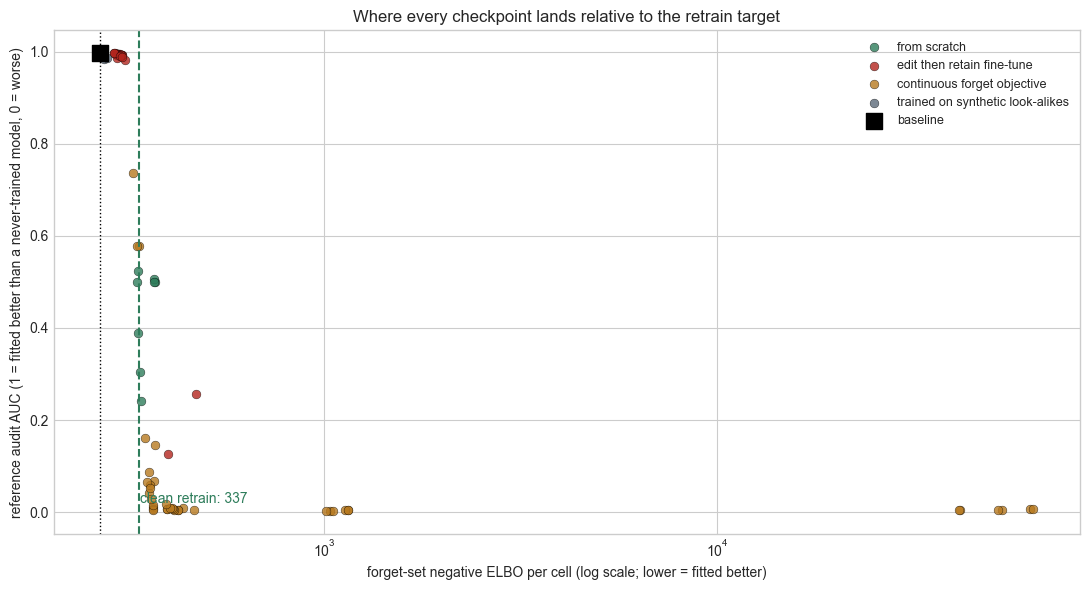

In [4]:
target = axis.loc[axis.method == 'retrain', 'forget_neg_elbo'].mean()
base_fe = axis.loc[axis.method == 'baseline', 'forget_neg_elbo'].iloc[0]
groups = {
    'from scratch': ['retrain', 'dp_sgd'],
    'edit then retain fine-tune': ['retain_finetune', 'gradient_ascent', 'ssd', 'scrub', 'moon', 'fisher', 'fisher_step_ablation'],
    'continuous forget objective': ['extragradient', 'extragradient_lambda1', 'contrastive', 'frozen_single_lambda5',
                                    'frozen_single_lambda10', 'frozen_multi_lambda5', 'frozen_multi_lambda10', 'rau'],
    'trained on synthetic look-alikes': ['augmentation'],
}
colors = {'from scratch': '#2E7D5B', 'edit then retain fine-tune': '#B3261E',
          'continuous forget objective': '#B7791F', 'trained on synthetic look-alikes': '#5C6B7A'}

fig, ax = plt.subplots(figsize=(11, 6))
for g, methods in groups.items():
    sub = axis[axis.method.isin(methods)]
    ax.scatter(sub.forget_neg_elbo, sub.lr_auc, s=40, alpha=0.8, color=colors[g], label=g, edgecolor='k', linewidth=0.3)
ax.scatter([base_fe], axis.loc[axis.method == 'baseline', 'lr_auc'], s=140, marker='s', color='k', label='baseline', zorder=5)
ax.axvline(target, color='#2E7D5B', ls='--', lw=1.5)
ax.text(target + 3, 0.02, f'clean retrain: {target:.0f}', color='#2E7D5B', fontsize=10)
ax.axvline(base_fe, color='k', ls=':', lw=1)
ax.set_xscale('log')
ax.set_xlabel('forget-set negative ELBO per cell (log scale; lower = fitted better)')
ax.set_ylabel('reference audit AUC (1 = fitted better than a never-trained model, 0 = worse)')
ax.set_title('Where every checkpoint lands relative to the retrain target')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'calibration_axis.png', dpi=150, bbox_inches='tight')
plt.show()

Read from left to right: the baseline (black square) fits the forget cells far better than the
never-seen level (dashed line); the edit-then-fine-tune methods sit just to its right, still fitted
better than the retrain fits them; the methods with a continuous forget-set objective sit to the right
of the line, fitted worse than a never-trained model; only the from-scratch models sit on it.

## Part B: likelihood-targeted unlearning

The objective adds, to the retain-set ELBO, a two-sided penalty on the gap between each forget cell's
negative ELBO and the model's own negative ELBO on that cell's ten nearest matched negatives. Adam at
1e-4, at most 50 passes over the retain set, stopping once the mean gap has stayed within 5 nats for
three epochs; the returned model is the one with the smallest mean absolute gap. Ten seeds at lambda = 1.

In [5]:
SEEDS = [42, 123, 456, 789, 1011, 1213, 1415, 1617, 1819, 2021]
LAMBDA = 1.0
ltu_dir = OUTPUT_DIR / 'ltu'
ltu_dir.mkdir(exist_ok=True)
histories, models = {}, {}
for sd in SEEDS:
    out = ltu_dir / f'seed{sd}'
    if (out / 'best_model.pt').exists():
        ck = torch.load(out / 'best_model.pt', map_location='cpu', weights_only=False)
        histories[sd] = ck['history']
        models[sd], _ = load_vae_model(str(out / 'best_model.pt'))
        print(f'seed {sd}: loaded')
        continue
    print(f'=== seed {sd} ===')
    model, hist = train_targeted(baseline, X_forget, X_matched, X_retain, neighbors, evaluator, TRAIN_DEVICE,
                                 lambda_target=LAMBDA, lr=1e-4, epochs=50, batch_size=256, tol=5.0, patience=3, seed=sd)
    out.mkdir(exist_ok=True)
    cfg = torch.load(BASELINE_CHECKPOINT, map_location='cpu', weights_only=False)['config']
    torch.save({'model_state_dict': model.to('cpu').state_dict(), 'config': cfg, 'history': hist,
                'method': 'likelihood_targeted', 'lambda_target': LAMBDA, 'seed': sd}, out / 'best_model.pt')
    histories[sd], models[sd] = hist, model.to('cpu')

seed 42: loaded
seed 123: loaded
seed 456: loaded
seed 789: loaded
seed 1011: loaded
seed 1213: loaded
seed 1415: loaded
seed 1617: loaded
seed 1819: loaded
seed 2021: loaded


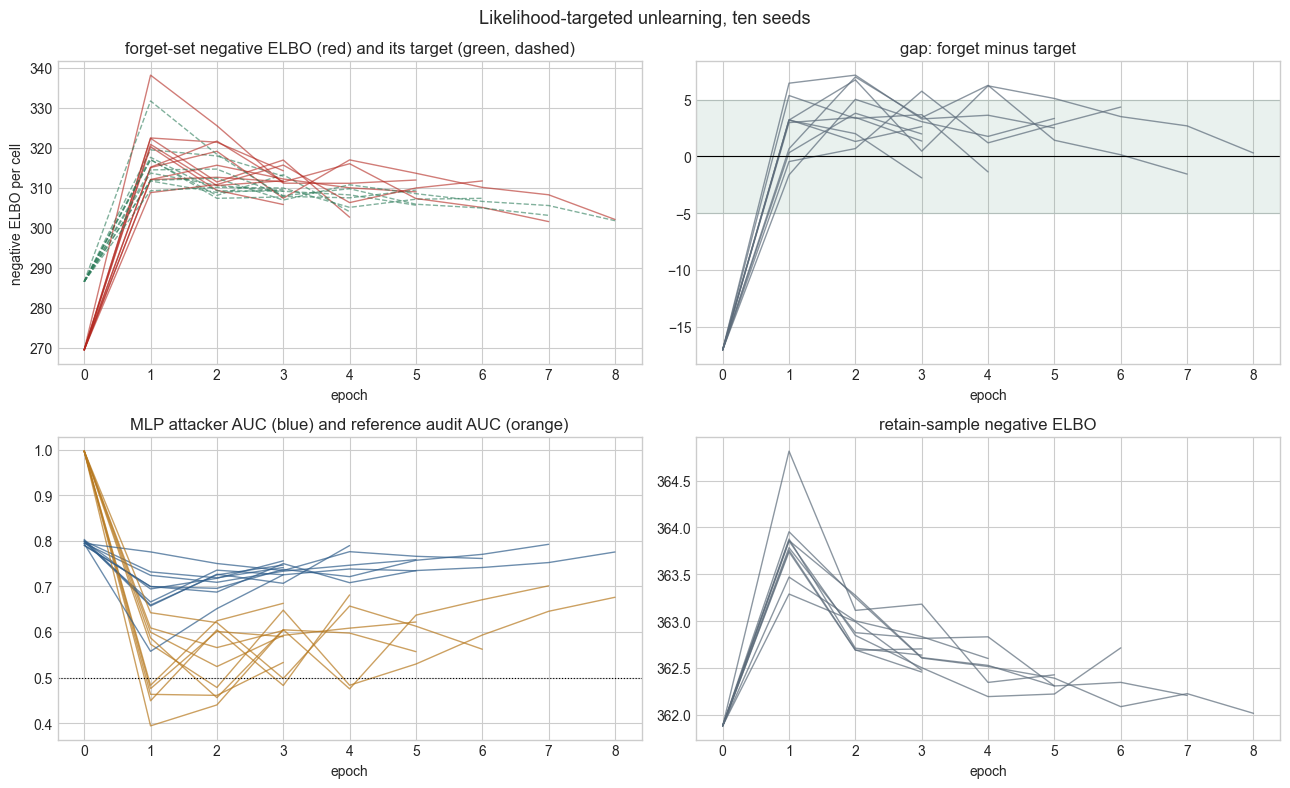

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for sd, h in histories.items():
    e = h['epoch']
    axes[0, 0].plot(e, h['forget_neg_elbo'], color='#B3261E', alpha=0.6, lw=1)
    axes[0, 0].plot(e, h['target_neg_elbo'], color='#2E7D5B', alpha=0.6, lw=1, ls='--')
    axes[0, 1].plot(e, h['gap'], color='#5C6B7A', alpha=0.7, lw=1)
    axes[1, 0].plot(e, h['mlp_auc'], color='#2F5D8A', alpha=0.7, lw=1)
    axes[1, 0].plot(e, h['lr_auc'], color='#B7791F', alpha=0.7, lw=1)
    axes[1, 1].plot(e, h['retain_neg_elbo'], color='#5C6B7A', alpha=0.7, lw=1)
axes[0, 0].set_title('forget-set negative ELBO (red) and its target (green, dashed)')
axes[0, 0].set_ylabel('negative ELBO per cell')
axes[0, 1].set_title('gap: forget minus target')
axes[0, 1].axhline(0, color='k', lw=0.8); axes[0, 1].axhspan(-5, 5, color='#2E7D5B', alpha=0.1)
axes[1, 0].set_title('MLP attacker AUC (blue) and reference audit AUC (orange)')
axes[1, 0].axhline(0.5, color='k', lw=0.8, ls=':')
axes[1, 1].set_title('retain-sample negative ELBO')
for a in axes.flat:
    a.set_xlabel('epoch')
plt.suptitle('Likelihood-targeted unlearning, ten seeds', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ltu_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
def nested_ci(recs, B=10000, seed=0):
    rng = np.random.RandomState(seed)
    arrs = [(np.array(s), np.array(l)) for s, l in recs]
    S = len(arrs); samples = np.empty(B)
    for b in range(B):
        v = []
        for di in (rng.randint(0, S, S) if S > 1 else [0]):
            s, l = arrs[di]; idx = rng.randint(0, len(s), len(s)); ls = l[idx]
            v.append(2 * abs(roc_auc_score(ls, s[idx]) - 0.5) if ls.min() != ls.max() else 0.0)
        samples[b] = np.mean(v)
    return float(np.percentile(samples, 2.5)), float(np.percentile(samples, 97.5))

final_rows, recs = [], []
for sd, model in models.items():
    m = evaluator(model, neighbors)
    rz = retain_latents(model, X_retain_sample, 'cpu')
    feats = torch.cat([attack_features(model, X_forget, rz, 'cpu'), attack_features(model, X_matched, rz, 'cpu')], 0)
    with torch.no_grad():
        scores = torch.sigmoid(attacker(feats).squeeze()).numpy()
    recs.append((scores, labels))
    u = evaluate_utility(model, X_holdout, labels_holdout, marker_idx, gene_names)
    final_rows.append({'seed': sd, 'epochs': histories[sd]['epoch'][-1], 'forget_neg_elbo': m['forget_neg_elbo'],
                       'target_neg_elbo': m['target_neg_elbo'], 'gap': m['gap'], 'mlp_auc': m['mlp_auc'],
                       'advantage': 2 * abs(m['mlp_auc'] - 0.5), 'lr_auc': m['lr_auc'],
                       'elbo': u['elbo'], 'kl': u['kl'], 'marker_r': u['marker_r'], 'ari': u['ari']})
final = pd.DataFrame(final_rows).set_index('seed')
ci = nested_ci(recs)
thr = pbmc_success_threshold()
rt = axis[axis.method == 'retrain']
lr_band = (rt.loc[rt.seed != 'seed_42', 'lr_auc'].min(), rt.loc[rt.seed != 'seed_42', 'lr_auc'].max())
print(f'mean advantage {final.advantage.mean():.3f}, nested 95% CI [{ci[0]:.3f}, {ci[1]:.3f}]; success threshold {thr:.3f}; '
      f'null floor {pbmc_null_floor()["mean"]:.3f}; retrain-versus-retrain audit band [{lr_band[0]:.3f}, {lr_band[1]:.3f}]')
final.round(3)

mean advantage 0.503, nested 95% CI [0.460, 0.550]; success threshold 0.182; null floor 0.091; retrain-versus-retrain audit band [0.242, 0.523]


,epochs,forget_neg_elbo,target_neg_elbo,gap,mlp_auc,advantage,lr_auc,elbo,kl,marker_r,ari
seed,,,,,,,,,,,
42,3,314.226,312.874,1.352,0.748,0.495,0.533,364.538,10.789,0.831,0.479
123,4,302.626,303.995,-1.369,0.781,0.563,0.681,364.693,10.731,0.831,0.483
456,5,312.026,313.660,-1.634,0.728,0.455,0.599,365.774,11.012,0.829,0.503
789,3,311.483,309.506,1.977,0.746,0.493,0.603,364.754,10.792,0.831,0.481
1011,3,305.794,307.689,-1.895,0.749,0.498,0.663,364.741,10.768,0.830,0.479
1213,3,310.542,309.229,1.314,0.732,0.465,0.601,364.702,10.875,0.830,0.486
1415,8,302.058,301.759,0.299,0.772,0.545,0.676,364.235,10.493,0.831,0.478
1617,5,311.912,309.409,2.503,0.742,0.483,0.557,364.519,10.955,0.830,0.484
1819,6,310.781,310.093,0.688,0.749,0.498,0.620,364.805,10.818,0.830,0.475


A seed passes the paper's rule when its advantage is at or below the retrain nested-CI upper bound
printed above, and it lands in the retrain band under the audit when its reference-LR AUC is inside the
retrain-versus-retrain range (the seeds other than the reference, printed above).

In [8]:
# Weight ablation on seed 42: does the outcome depend on how hard the target is enforced?
abl = {}
for lam in [0.3, 3.0]:
    out = ltu_dir / f'lambda{lam}_seed42'
    if (out / 'best_model.pt').exists():
        ck = torch.load(out / 'best_model.pt', map_location='cpu', weights_only=False)
        model, hist = load_vae_model(str(out / 'best_model.pt'))[0], ck['history']
    else:
        print(f'=== lambda {lam} ===')
        model, hist = train_targeted(baseline, X_forget, X_matched, X_retain, neighbors, evaluator, TRAIN_DEVICE,
                                     lambda_target=lam, lr=1e-4, epochs=50, tol=5.0, patience=3, seed=42)
        out.mkdir(exist_ok=True)
        cfg = torch.load(BASELINE_CHECKPOINT, map_location='cpu', weights_only=False)['config']
        torch.save({'model_state_dict': model.to('cpu').state_dict(), 'config': cfg, 'history': hist,
                    'method': 'likelihood_targeted', 'lambda_target': lam, 'seed': 42}, out / 'best_model.pt')
    m = evaluator(model.to('cpu'), neighbors)
    u = evaluate_utility(model, X_holdout, labels_holdout, marker_idx, gene_names)
    abl[lam] = {'epochs': hist['epoch'][-1], **{k: m[k] for k in ['forget_neg_elbo', 'target_neg_elbo', 'gap', 'mlp_auc', 'lr_auc']},
                'elbo': u['elbo'], 'marker_r': u['marker_r']}
abl[1.0] = {'epochs': final.epochs.loc[42], **final.loc[42, ['forget_neg_elbo', 'target_neg_elbo', 'gap', 'mlp_auc', 'lr_auc', 'elbo', 'marker_r']].to_dict()}
pd.DataFrame(abl).T.sort_index().round(3)

,epochs,forget_neg_elbo,target_neg_elbo,gap,mlp_auc,lr_auc,elbo,marker_r
0.3,4.0,309.746,308.886,0.860,0.772,0.591,364.205,0.831
1.0,3.0,314.226,312.874,1.352,0.748,0.533,364.538,0.831
3.0,3.0,318.985,317.834,1.151,0.724,0.498,365.384,0.830


## Part C: the cohort-average target

The look-alike target of Part B is the model's own fit of the ten matched negatives nearest to each
forget cell. Part A shows where that sits: the baseline fits those look-alikes far better than it fits
the average matched cell, because the look-alikes live in the region the memorized cells shaped. The
clean retrain, which has no knowledge of the subpopulation, fits the forget cells at the cohort
average. Part C therefore sets the target to the model's own negative ELBO averaged over all matched
negatives, the same for every forget cell, with everything else unchanged.

In [9]:
neighbors_all = torch.arange(len(X_matched)).repeat(len(X_forget), 1)   # every forget cell -> all matched negatives
avg_dir = OUTPUT_DIR / 'ltu_avg'
avg_dir.mkdir(exist_ok=True)
histories_avg, models_avg = {}, {}
for sd in SEEDS:
    out = avg_dir / f'seed{sd}'
    if (out / 'best_model.pt').exists():
        ck = torch.load(out / 'best_model.pt', map_location='cpu', weights_only=False)
        histories_avg[sd] = ck['history']
        models_avg[sd], _ = load_vae_model(str(out / 'best_model.pt'))
        print(f'seed {sd}: loaded')
        continue
    print(f'=== seed {sd} (cohort-average target) ===')
    model, hist = train_targeted(baseline, X_forget, X_matched, X_retain, neighbors_all, evaluator, TRAIN_DEVICE,
                                 lambda_target=LAMBDA, lr=1e-4, epochs=50, batch_size=256, tol=5.0, patience=3, seed=sd)
    out.mkdir(exist_ok=True)
    cfg = torch.load(BASELINE_CHECKPOINT, map_location='cpu', weights_only=False)['config']
    torch.save({'model_state_dict': model.to('cpu').state_dict(), 'config': cfg, 'history': hist,
                'method': 'likelihood_targeted_cohort_average', 'lambda_target': LAMBDA, 'seed': sd}, out / 'best_model.pt')
    histories_avg[sd], models_avg[sd] = hist, model.to('cpu')

seed 42: loaded
seed 123: loaded
seed 456: loaded
seed 789: loaded
seed 1011: loaded
seed 1213: loaded
seed 1415: loaded
seed 1617: loaded
seed 1819: loaded
seed 2021: loaded


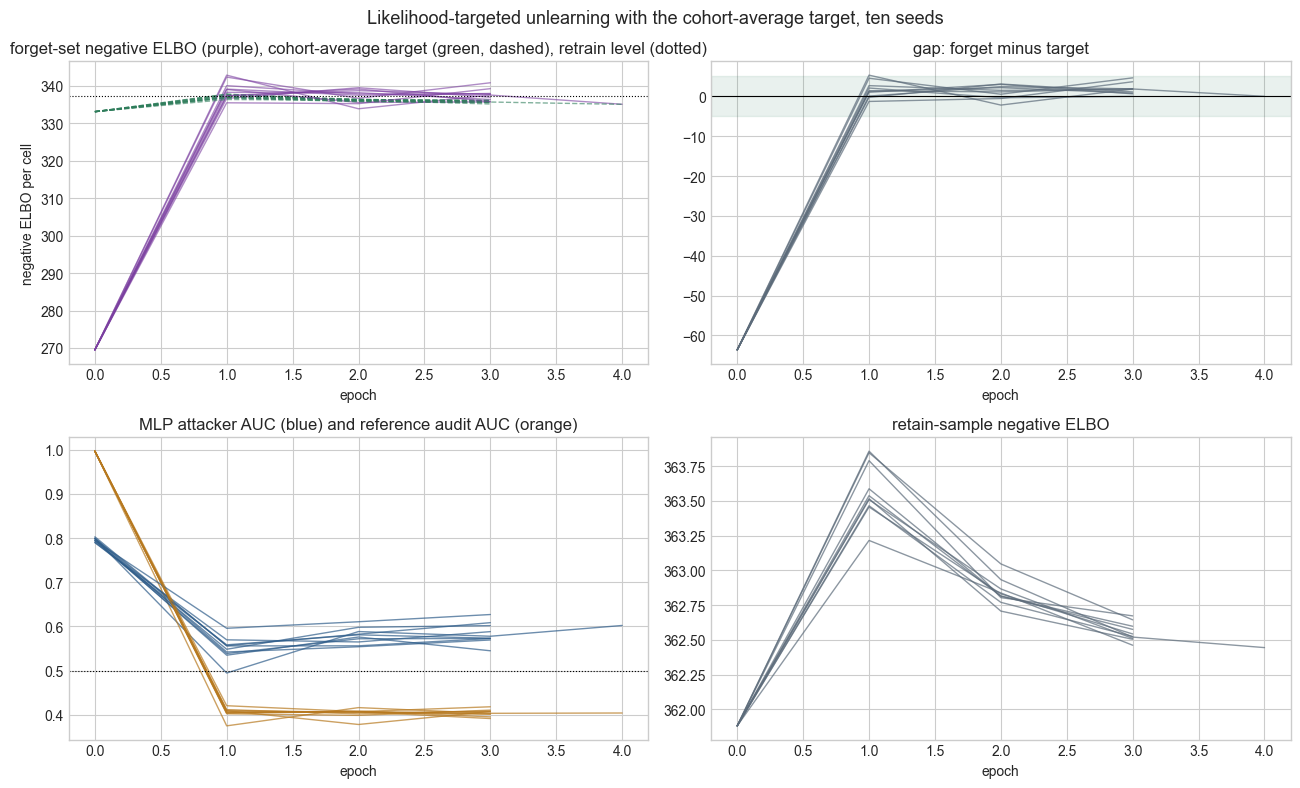

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for sd, h in histories_avg.items():
    e = h['epoch']
    axes[0, 0].plot(e, h['forget_neg_elbo'], color='#7B3FA0', alpha=0.6, lw=1)
    axes[0, 0].plot(e, h['target_neg_elbo'], color='#2E7D5B', alpha=0.6, lw=1, ls='--')
    axes[0, 1].plot(e, h['gap'], color='#5C6B7A', alpha=0.7, lw=1)
    axes[1, 0].plot(e, h['mlp_auc'], color='#2F5D8A', alpha=0.7, lw=1)
    axes[1, 0].plot(e, h['lr_auc'], color='#B7791F', alpha=0.7, lw=1)
    axes[1, 1].plot(e, h['retain_neg_elbo'], color='#5C6B7A', alpha=0.7, lw=1)
axes[0, 0].axhline(target, color='k', lw=0.8, ls=':')
axes[0, 0].set_title('forget-set negative ELBO (purple), cohort-average target (green, dashed), retrain level (dotted)')
axes[0, 0].set_ylabel('negative ELBO per cell')
axes[0, 1].set_title('gap: forget minus target')
axes[0, 1].axhline(0, color='k', lw=0.8); axes[0, 1].axhspan(-5, 5, color='#2E7D5B', alpha=0.1)
axes[1, 0].set_title('MLP attacker AUC (blue) and reference audit AUC (orange)')
axes[1, 0].axhline(0.5, color='k', lw=0.8, ls=':')
axes[1, 1].set_title('retain-sample negative ELBO')
for a in axes.flat:
    a.set_xlabel('epoch')
plt.suptitle('Likelihood-targeted unlearning with the cohort-average target, ten seeds', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ltu_avg_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
final_rows, recs_avg = [], []
for sd, model in models_avg.items():
    m = evaluator(model, neighbors_all)
    rz = retain_latents(model, X_retain_sample, 'cpu')
    feats = torch.cat([attack_features(model, X_forget, rz, 'cpu'), attack_features(model, X_matched, rz, 'cpu')], 0)
    with torch.no_grad():
        scores = torch.sigmoid(attacker(feats).squeeze()).numpy()
    recs_avg.append((scores, labels))
    u = evaluate_utility(model, X_holdout, labels_holdout, marker_idx, gene_names)
    final_rows.append({'seed': sd, 'epochs': histories_avg[sd]['epoch'][-1], 'forget_neg_elbo': m['forget_neg_elbo'],
                       'target_neg_elbo': m['target_neg_elbo'], 'gap': m['gap'], 'mlp_auc': m['mlp_auc'],
                       'advantage': 2 * abs(m['mlp_auc'] - 0.5), 'lr_auc': m['lr_auc'],
                       'elbo': u['elbo'], 'kl': u['kl'], 'marker_r': u['marker_r'], 'ari': u['ari']})
final_avg = pd.DataFrame(final_rows).set_index('seed')
ci_avg = nested_ci(recs_avg)
print(f'cohort-average target: mean advantage {final_avg.advantage.mean():.3f}, nested 95% CI [{ci_avg[0]:.3f}, {ci_avg[1]:.3f}]; '
      f'success threshold {thr:.3f}; retrain-versus-retrain audit band [{lr_band[0]:.3f}, {lr_band[1]:.3f}]')
final_avg.round(3)

cohort-average target: mean advantage 0.166, nested 95% CI [0.111, 0.212]; success threshold 0.182; retrain-versus-retrain audit band [0.242, 0.523]


,epochs,forget_neg_elbo,target_neg_elbo,gap,mlp_auc,advantage,lr_auc,elbo,kl,marker_r,ari
seed,,,,,,,,,,,
42,3,337.869,336.359,1.511,0.583,0.166,0.407,364.986,11.044,0.830,0.487
123,4,335.100,335.082,0.019,0.601,0.201,0.404,364.570,11.006,0.831,0.491
456,3,337.519,336.391,1.128,0.579,0.158,0.407,365.070,11.020,0.830,0.474
789,3,338.284,337.005,1.279,0.551,0.102,0.403,365.490,11.123,0.830,0.477
1011,3,337.361,337.286,0.074,0.563,0.127,0.410,365.606,11.098,0.830,0.480
1213,3,336.700,336.155,0.545,0.570,0.140,0.407,364.873,10.979,0.830,0.485
1415,3,336.664,336.908,-0.245,0.562,0.125,0.409,365.563,11.015,0.830,0.505
1617,3,335.742,335.738,0.004,0.600,0.199,0.418,364.649,10.874,0.831,0.475
1819,3,335.824,335.178,0.646,0.632,0.264,0.409,364.467,10.789,0.830,0.477


Two questions for the table above. Under the audit, do the forget cells now sit in the retrain band?
Under the attacker, does calibrating the likelihood to the retrain level remove the membership signal
that the attacker reads from the seventy latent features?

## Part D: calibration on look-alikes the evaluation never sees

Part C calibrated the forget cells against the evaluation's own matched negatives. A method that is
scored against the cells it calibrated on gets an optimistic reading. Part D draws the calibration
set from the unseen cells ranked 11 to 30 nearest to each forget cell in the baseline's latent space,
which by construction excludes every evaluation negative (the 194 matched cells are the ten nearest),
and keeps everything else as in Part C. The evaluator still scores against the canonical negatives.

In [12]:
from sklearn.neighbors import NearestNeighbors
baseline.eval()
with torch.no_grad():
    mu_f, _ = baseline.encode(X_forget)
    mu_u, _ = baseline.encode(X[unseen_idx])
_, idx_u = NearestNeighbors(n_neighbors=30).fit(mu_u.numpy()).kneighbors(mu_f.numpy())
unseen_arr = np.asarray(unseen_idx)
calib_idx = sorted({int(unseen_arr[j]) for row in idx_u for j in row} - set(int(i) for i in matched_idx))
X_calib = X[calib_idx]
neighbors_calib = torch.arange(len(X_calib)).repeat(len(X_forget), 1)
print(f'calibration look-alikes: {len(calib_idx)} unseen cells (ranks 11 to 30); overlap with evaluation negatives: '
      f'{len(set(calib_idx) & set(int(i) for i in matched_idx))}')
dis_dir = OUTPUT_DIR / 'ltu_disjoint'
dis_dir.mkdir(exist_ok=True)
histories_dis, models_dis = {}, {}
for sd in SEEDS:
    out = dis_dir / f'seed{sd}'
    if (out / 'best_model.pt').exists():
        ck = torch.load(out / 'best_model.pt', map_location='cpu', weights_only=False)
        histories_dis[sd] = ck['history']
        models_dis[sd], _ = load_vae_model(str(out / 'best_model.pt'))
        print(f'seed {sd}: loaded')
        continue
    print(f'=== seed {sd} (disjoint calibration set) ===')
    model, hist = train_targeted(baseline, X_forget, X_calib, X_retain, neighbors_calib, evaluator, TRAIN_DEVICE,
                                 lambda_target=LAMBDA, lr=1e-4, epochs=50, batch_size=256, tol=5.0, patience=3, seed=sd,
                                 eval_neighbors=neighbors_all)
    out.mkdir(exist_ok=True)
    cfg = torch.load(BASELINE_CHECKPOINT, map_location='cpu', weights_only=False)['config']
    torch.save({'model_state_dict': model.to('cpu').state_dict(), 'config': cfg, 'history': hist,
                'method': 'likelihood_targeted_disjoint_calibration', 'lambda_target': LAMBDA, 'seed': sd,
                'calibration_indices': calib_idx}, out / 'best_model.pt')
    histories_dis[sd], models_dis[sd] = hist, model.to('cpu')

calibration look-alikes: 88 unseen cells (ranks 11 to 30); overlap with evaluation negatives: 0
=== seed 42 (disjoint calibration set) ===


  epoch 0: forget=269.5 target=333.1 gap=-63.6 MLP=0.799 LR=0.996


  epoch 1: forget=303.5 target=337.4 gap=-33.9 retain=363.5 MLP=0.805 LR=0.639
    objective gap (calibration cells) +5.8


  epoch 2: forget=297.9 target=335.9 gap=-38.0 retain=362.7 MLP=0.843 LR=0.694
    objective gap (calibration cells) +2.0


  epoch 3: forget=296.8 target=335.4 gap=-38.6 retain=362.4 MLP=0.853 LR=0.686
    objective gap (calibration cells) +1.5


  epoch 4: forget=296.2 target=335.2 gap=-39.0 retain=362.4 MLP=0.861 LR=0.688
    objective gap (calibration cells) +1.4
  stop at epoch 4: |gap| < 5.0 for 3 epochs
=== seed 123 (disjoint calibration set) ===


... (32 outputs left out)

  epoch 0: forget=269.5 target=333.1 gap=-63.6 MLP=0.790 LR=0.996


  epoch 1: forget=298.6 target=336.6 gap=-38.0 retain=363.5 MLP=0.791 LR=0.687
    objective gap (calibration cells) +0.9


  epoch 2: forget=296.2 target=335.6 gap=-39.5 retain=363.0 MLP=0.826 LR=0.689
    objective gap (calibration cells) +0.1


  epoch 3: forget=297.7 target=335.0 gap=-37.3 retain=362.7 MLP=0.823 LR=0.667
    objective gap (calibration cells) +2.4
  stop at epoch 3: |gap| < 5.0 for 3 epochs


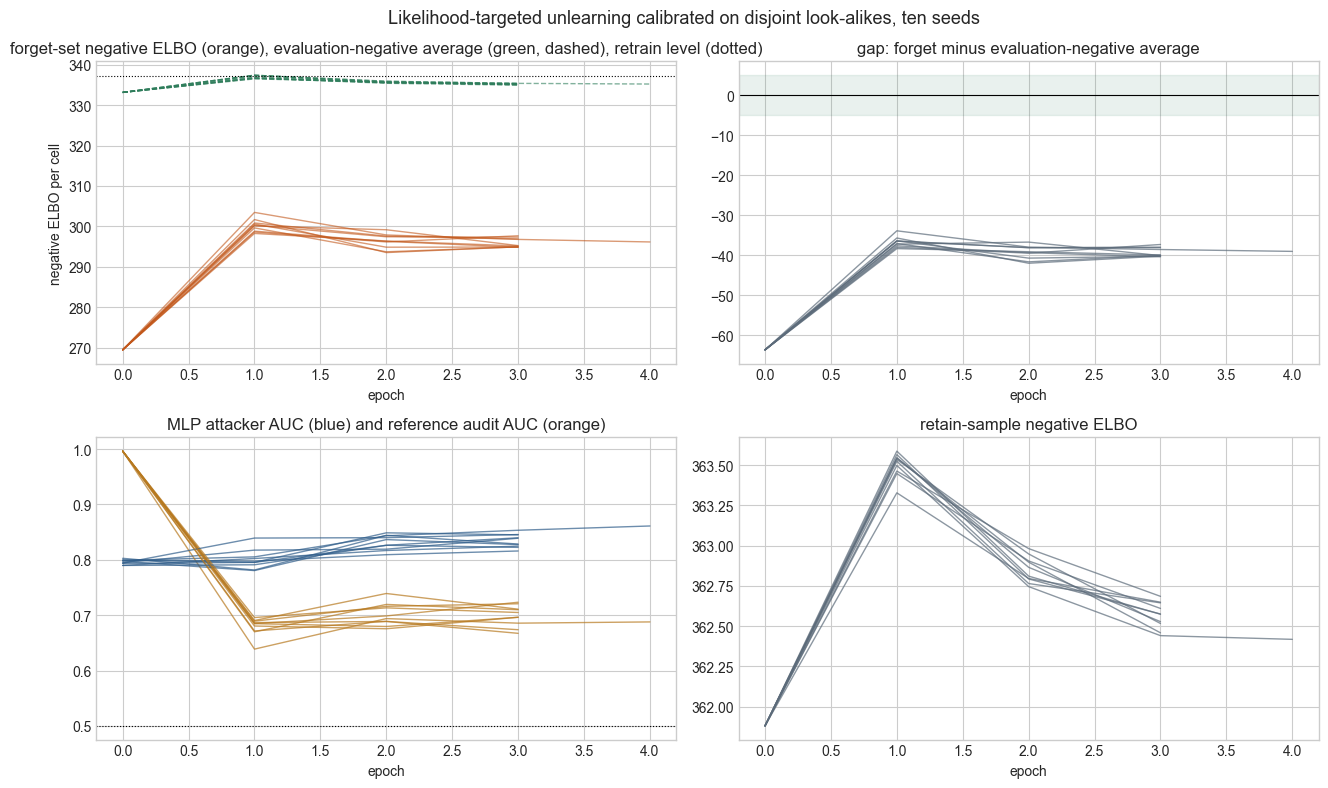

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for sd, h in histories_dis.items():
    e = h['epoch']
    axes[0, 0].plot(e, h['forget_neg_elbo'], color='#C2571A', alpha=0.6, lw=1)
    axes[0, 0].plot(e, h['target_neg_elbo'], color='#2E7D5B', alpha=0.6, lw=1, ls='--')
    axes[0, 1].plot(e, h['gap'], color='#5C6B7A', alpha=0.7, lw=1)
    axes[1, 0].plot(e, h['mlp_auc'], color='#2F5D8A', alpha=0.7, lw=1)
    axes[1, 0].plot(e, h['lr_auc'], color='#B7791F', alpha=0.7, lw=1)
    axes[1, 1].plot(e, h['retain_neg_elbo'], color='#5C6B7A', alpha=0.7, lw=1)
axes[0, 0].axhline(target, color='k', lw=0.8, ls=':')
axes[0, 0].set_title('forget-set negative ELBO (orange), evaluation-negative average (green, dashed), retrain level (dotted)')
axes[0, 0].set_ylabel('negative ELBO per cell')
axes[0, 1].set_title('gap: forget minus evaluation-negative average')
axes[0, 1].axhline(0, color='k', lw=0.8); axes[0, 1].axhspan(-5, 5, color='#2E7D5B', alpha=0.1)
axes[1, 0].set_title('MLP attacker AUC (blue) and reference audit AUC (orange)')
axes[1, 0].axhline(0.5, color='k', lw=0.8, ls=':')
axes[1, 1].set_title('retain-sample negative ELBO')
for a in axes.flat:
    a.set_xlabel('epoch')
plt.suptitle('Likelihood-targeted unlearning calibrated on disjoint look-alikes, ten seeds', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ltu_disjoint_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
from likelihood_audit import neg_elbo_per_cell as audit_neg_elbo
final_rows, recs_dis = [], []
for sd, model in models_dis.items():
    m = evaluator(model, neighbors_all)
    rz = retain_latents(model, X_retain_sample, 'cpu')
    feats = torch.cat([attack_features(model, X_forget, rz, 'cpu'), attack_features(model, X_matched, rz, 'cpu')], 0)
    with torch.no_grad():
        scores = torch.sigmoid(attacker(feats).squeeze()).numpy()
    recs_dis.append((scores, labels))
    u = evaluate_utility(model, X_holdout, labels_holdout, marker_idx, gene_names)
    final_rows.append({'seed': sd, 'epochs': histories_dis[sd]['epoch'][-1], 'forget_neg_elbo': m['forget_neg_elbo'],
                       'calib_neg_elbo': float(audit_neg_elbo(model, X_calib).mean()),
                       'matched_neg_elbo': m['matched_neg_elbo'], 'gap_to_matched': m['gap'], 'mlp_auc': m['mlp_auc'],
                       'advantage': 2 * abs(m['mlp_auc'] - 0.5), 'lr_auc': m['lr_auc'],
                       'elbo': u['elbo'], 'kl': u['kl'], 'marker_r': u['marker_r'], 'ari': u['ari']})
final_dis = pd.DataFrame(final_rows).set_index('seed')
ci_dis = nested_ci(recs_dis)
print(f'disjoint calibration: mean advantage {final_dis.advantage.mean():.3f}, nested 95% CI [{ci_dis[0]:.3f}, {ci_dis[1]:.3f}]; '
      f'success threshold {thr:.3f}; retrain-versus-retrain audit band [{lr_band[0]:.3f}, {lr_band[1]:.3f}]')
final_dis.round(3)

disjoint calibration: mean advantage 0.668, nested 95% CI [0.630, 0.700]; success threshold 0.182; retrain-versus-retrain audit band [0.242, 0.523]


,epochs,forget_neg_elbo,calib_neg_elbo,matched_neg_elbo,gap_to_matched,mlp_auc,advantage,lr_auc,elbo,kl,marker_r,ari
seed,,,,,,,,,,,,
42,4,296.160,294.768,335.194,-39.034,0.863,0.725,0.688,364.422,10.906,0.830,0.483
123,3,294.845,294.954,335.230,-40.385,0.834,0.669,0.723,364.882,11.146,0.831,0.476
456,3,295.254,295.219,335.343,-40.088,0.845,0.690,0.696,364.602,11.093,0.830,0.489
789,3,297.439,296.048,335.532,-38.092,0.816,0.633,0.680,364.925,11.120,0.830,0.493
1011,3,294.937,295.044,334.921,-39.984,0.823,0.646,0.711,364.630,10.946,0.830,0.480
1213,3,294.961,295.239,335.190,-40.229,0.826,0.653,0.710,364.645,11.066,0.830,0.475
1415,3,295.179,295.117,335.113,-39.934,0.826,0.652,0.721,364.620,10.971,0.830,0.482
1617,3,294.898,294.700,335.152,-40.254,0.840,0.680,0.705,364.683,11.025,0.831,0.468
1819,3,297.604,296.377,335.730,-38.126,0.837,0.674,0.689,364.997,10.907,0.830,0.484


The calibration cells' own level (`calib_neg_elbo`) can differ from the evaluation negatives' level
(`matched_neg_elbo`); the gap column measures the forget cells against the evaluation negatives, which
the method never used.

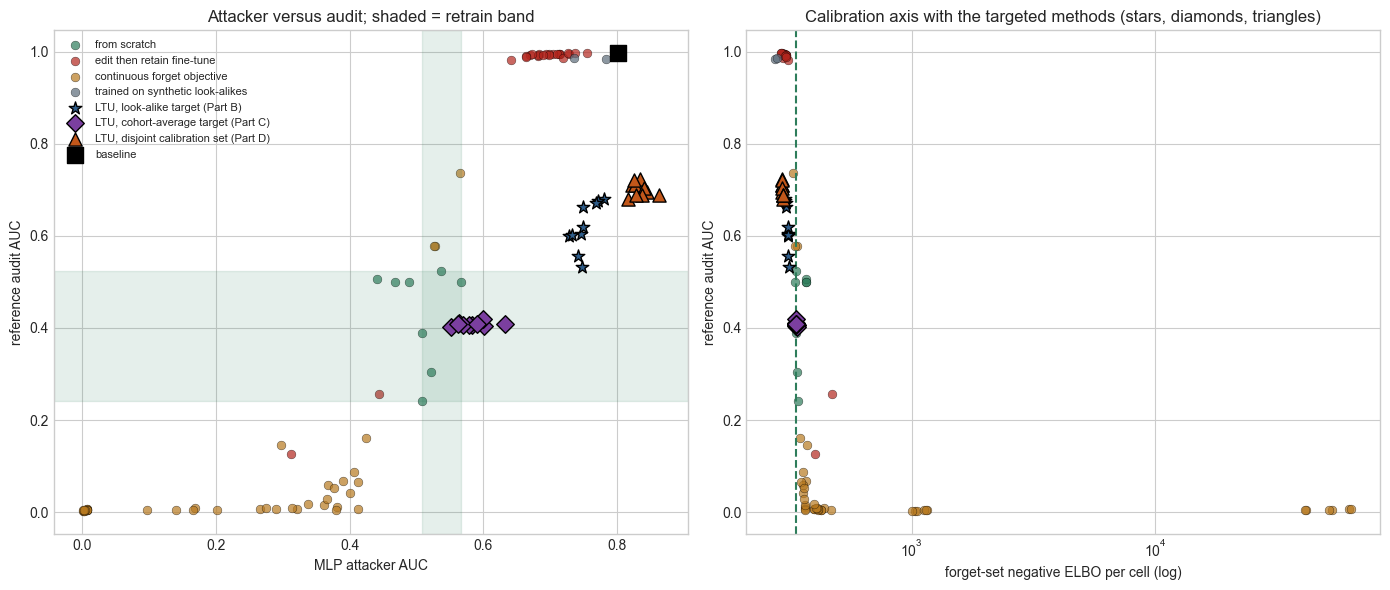

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# left: MLP vs LR for every family, LTU added
ax = axes[0]
for g, methods in groups.items():
    sub = axis[axis.method.isin(methods)]
    ax.scatter(sub.mlp_auc, sub.lr_auc, s=40, alpha=0.7, color=colors[g], label=g, edgecolor='k', linewidth=0.3)
ax.scatter(final.mlp_auc, final.lr_auc, s=90, marker='*', color='#2F5D8A', edgecolor='k', label='LTU, look-alike target (Part B)', zorder=6)
ax.scatter(final_avg.mlp_auc, final_avg.lr_auc, s=80, marker='D', color='#7B3FA0', edgecolor='k', label='LTU, cohort-average target (Part C)', zorder=6)
ax.scatter(final_dis.mlp_auc, final_dis.lr_auc, s=90, marker='^', color='#C2571A', edgecolor='k', label='LTU, disjoint calibration set (Part D)', zorder=6)
ax.scatter(axis.loc[axis.method == 'baseline', 'mlp_auc'], axis.loc[axis.method == 'baseline', 'lr_auc'], s=140, marker='s', color='k', label='baseline', zorder=5)
rt = axis[axis.method == 'retrain']
ax.axvspan(rt.mlp_auc.min(), rt.mlp_auc.max(), color='#2E7D5B', alpha=0.12)
band = rt.loc[rt.seed != 'seed_42', 'lr_auc']   # seed 42 is the reference and scores 0.5 against itself
ax.axhspan(band.min(), band.max(), color='#2E7D5B', alpha=0.12)
ax.set_xlabel('MLP attacker AUC'); ax.set_ylabel('reference audit AUC')
ax.set_title('Attacker versus audit; shaded = retrain band')
ax.legend(fontsize=8, loc='upper left')
# right: calibration axis with LTU
ax = axes[1]
for g, methods in groups.items():
    sub = axis[axis.method.isin(methods)]
    ax.scatter(sub.forget_neg_elbo, sub.lr_auc, s=40, alpha=0.7, color=colors[g], edgecolor='k', linewidth=0.3)
ax.scatter(final.forget_neg_elbo, final.lr_auc, s=90, marker='*', color='#2F5D8A', edgecolor='k', zorder=6)
ax.scatter(final_avg.forget_neg_elbo, final_avg.lr_auc, s=80, marker='D', color='#7B3FA0', edgecolor='k', zorder=6)
ax.scatter(final_dis.forget_neg_elbo, final_dis.lr_auc, s=90, marker='^', color='#C2571A', edgecolor='k', zorder=6)
ax.axvline(target, color='#2E7D5B', ls='--', lw=1.5)
ax.set_xscale('log')
ax.set_xlabel('forget-set negative ELBO per cell (log)'); ax.set_ylabel('reference audit AUC')
ax.set_title('Calibration axis with the targeted methods (stars, diamonds, triangles)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ltu_calibration_axis.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
results = {
    'method': 'likelihood_targeted_unlearning',
    'objective': 'ELBO(retain) + lambda * mean_i |negELBO(x_i) - mean_{j in kNN_i} negELBO(x_j)|, k=10 matched negatives, two-sided',
    'lambda': LAMBDA, 'seeds': SEEDS, 'stop_rule': '|mean gap| < 5 nats for 3 epochs, best = smallest mean |gap|',
    'reference': str(REF_PATH), 'attacker': 'canonical fresh attacker on the July-4 baseline, CPU',
    'per_seed': final.reset_index().to_dict('records'),
    'mean_advantage': float(final.advantage.mean()), 'advantage_nested_ci': list(ci),
    'success_threshold': float(thr),
    'lambda_ablation_seed42': abl,
    'cohort_average_target': {'objective': 'ELBO(retain) + lambda * mean_i |negELBO(x_i) - mean_{all matched} negELBO(x_j)|',
                              'per_seed': final_avg.reset_index().to_dict('records'),
                              'mean_advantage': float(final_avg.advantage.mean()), 'advantage_nested_ci': list(ci_avg)},
    'disjoint_calibration_target': {'objective': 'as cohort_average_target, calibration cells = unseen ranks 11 to 30 nearest each forget cell, none of them evaluation negatives',
                                    'n_calibration_cells': len(calib_idx),
                                    'per_seed': final_dis.reset_index().to_dict('records'),
                                    'mean_advantage': float(final_dis.advantage.mean()), 'advantage_nested_ci': list(ci_dis)},
    'calibration_axis_summary': summary.reset_index().to_dict('records'),
    'retrain_target_neg_elbo': float(target),
    'retrain_vs_retrain_lr_band': list(lr_band),
    'estimator': 'likelihood_audit.neg_elbo_per_cell (eval mode, 16 seeded z samples)',
}
with open(OUTPUT_DIR / 'targeted_unlearning.json', 'w') as f:
    json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print(f"saved {OUTPUT_DIR / 'targeted_unlearning.json'}")

saved ../outputs/p7/targeted_unlearning.json


## Summary

| Output | Path |
|---|---|
| Calibration axis, every checkpoint | `outputs/p7/calibration_axis.csv`, `outputs/p7/calibration_axis.png` |
| Look-alike target (Part B): checkpoints, curves | `outputs/p7/ltu/seed*/best_model.pt`, `outputs/p7/ltu_training_curves.png` |
| Cohort-average target (Part C): checkpoints, curves | `outputs/p7/ltu_avg/seed*/best_model.pt`, `outputs/p7/ltu_avg_training_curves.png` |
| Disjoint calibration set (Part D): checkpoints, curves | `outputs/p7/ltu_disjoint/seed*/best_model.pt`, `outputs/p7/ltu_disjoint_training_curves.png` |
| Attacker versus audit, and the axis with the three variants | `outputs/p7/ltu_calibration_axis.png` |
| Results JSON | `outputs/p7/targeted_unlearning.json` |

**What the three targets show.** Every post-hoc method in Part A lands short of the retrain level or
past it, at no utility cost. The two targeted variants that calibrate on held-out look-alikes (Parts B
and D) land short as well, and for a reason the tables make visible: the model and the clean retrain
alike fit the nearest look-alikes of a megakaryocyte far better than the clean retrain fits the
megakaryocyte itself, because the retrain knows the neighbours' cell types and has no knowledge of the
forget cells' type. Calibrating to look-alikes therefore reproduces the baseline's treatment of the
forget cells, with the attacker at or above the baseline's AUC and the audit above the retrain band.

Part C, whose target coincides with the retrain's level on this cohort, is the one post-hoc run in the
study that lands inside the retrain band under the audit and brings the attacker's advantage down to
the paper's threshold, at baseline utility. The missing ingredient is the level itself, not a
signature the attacker can always find. That level is the fit of a cell type the model does not know,
and no cell the model does know supplies it; Part C could read it off the evaluation's own negatives
only because their average happens to match the retrain's level here, which is also why its reading is
optimistic. Without a retrain, the target is not observable.
